# Paper 22: Book drawdown brake

v2 still lost about **−21% in 2022** with the SPY 200-day on, and about **−19% inside 2020**. The switch looks at SPY, not at *this* NAV. The mandate is steady growth of this book.

This paper **turns the SMA off** (`overlay.kind = none`) and cuts equity when the book's own NAV is `X%` below its peak. Stay braked until NAV has recovered half of that loss. Ladder `X` in {8, 12, 15, 20}. One extra trial keeps half the stock book while braked (`nav_brake_off=0.5`).

Change only `overlay`. Brain, construction, execution, and screens stay on v2. Kill it if it chops 2023–24 to pieces, or if it is just the SMA in a costume.

Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** nav-8, nav-12, nav-15, nav-20, nav-12-half.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-22-nav-brake", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="22-nav-brake",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545


        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


## One trailing stop at a time


In [2]:
nav_8 = run_book("fcf-sma-v2-baseline", rd, paper="22-nav-brake", id="nav-8", overlay={"kind": "none", "nav_brake": 0.08})
nav_12 = run_book("fcf-sma-v2-baseline", rd, paper="22-nav-brake", id="nav-12", overlay={"kind": "none", "nav_brake": 0.12})
nav_15 = run_book("fcf-sma-v2-baseline", rd, paper="22-nav-brake", id="nav-15", overlay={"kind": "none", "nav_brake": 0.15})
nav_20 = run_book("fcf-sma-v2-baseline", rd, paper="22-nav-brake", id="nav-20", overlay={"kind": "none", "nav_brake": 0.20})
nav_12_half = run_book("fcf-sma-v2-baseline", rd, paper="22-nav-brake", id="nav-12-half", overlay={"kind": "none", "nav_brake": 0.12, "nav_brake_off": 0.5})
trials = [nav_8, nav_12, nav_15, nav_20, nav_12_half]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))


v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date', 'cash yield': 'none'}
nav-8 cfe8baf1970c
  {'book': 'nav-8', 'hash': 'cfe8baf1970c', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'none, NAV brake 8% to 0%', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10

In [3]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
nav-8,-0.0510,-0.0077,0.0288,-0.1128,-0.0686,-0.9505,-1.0811,0.1874,0.0025,0.0039,0.0230,1.0000,cfe8baf1970c
nav-12,-0.0938,-0.0145,0.0539,-0.1670,-0.0870,-0.6166,-0.7944,0.2070,0.0028,0.0047,0.0272,1.0000,7050511e3312
nav-15,-0.0938,-0.0145,0.0539,-0.1670,-0.0870,-0.6166,-0.7944,0.2070,0.0028,0.0047,0.0272,1.0000,7cda6d1de0ee
nav-20,-0.2151,-0.0354,0.0879,-0.2606,-0.1356,-0.5937,-0.7283,0.2300,0.0031,0.0057,0.0290,1.0000,2a065816ccf4
nav-12-half,1.1737,0.1223,0.1616,-0.2257,0.5419,0.6732,0.8770,2.1710,0.0292,0.0564,0.8035,8.0000,e195e7bba76d
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


nav-8 KILLED train Calmar below both v2 baseline and SPUS; 2023 calendar more than 15pp worse than v2 baseline
nav-12 KILLED train Calmar below both v2 baseline and SPUS; 2023 calendar more than 15pp worse than v2 baseline
nav-15 KILLED train Calmar below both v2 baseline and SPUS; 2023 calendar more than 15pp worse than v2 baseline
nav-20 KILLED train Calmar below both v2 baseline and SPUS; 2023 calendar more than 15pp worse than v2 baseline
nav-12-half keep pass


## Did the brake bind?

Count cuts, days not fully invested, and whether 2020/2022 actually fired. `regime()` is always-on; the cut lives in `step`.


In [5]:
import pandas as pd
from monterey.diagnostics.attribution import switch_cost

spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()
rows = []
for book in [base, *trials]:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    cost = switch_cost(nav, spus)
    events = book.events
    rows.append({
        "book": book.spec.id,
        "avg_exposure": float(nav["exposure"].mean()),
        "cuts": cost["cuts"],
        "days_not_invested": cost["days_not_invested"],
        "near_cash_days": int((nav["invested"] / nav["nav"] < 0.05).sum()),
        "nav_brake_events": int(events["symbol"].astype(str).str.contains("NAV brake").sum()) if events is not None and not events.empty else 0,
        "max_drawdown": float((book.nav_series() / book.nav_series().cummax() - 1).min()),
    })
pd.DataFrame(rows).set_index("book")


,avg_exposure,cuts,days_not_invested,near_cash_days,nav_brake_events,max_drawdown
book,,,,,,
v2,0.8032,18,352,333,0,-0.2482
nav-8,0.0230,1,1654,1652,1,-0.1128
nav-12,0.0272,1,1647,1645,1,-0.1670
nav-15,0.0272,1,1647,1645,1,-0.1670
nav-20,0.0290,1,1644,1642,1,-0.2606
nav-12-half,0.8035,4,670,0,8,-0.2257


## Path, not just the scorecard


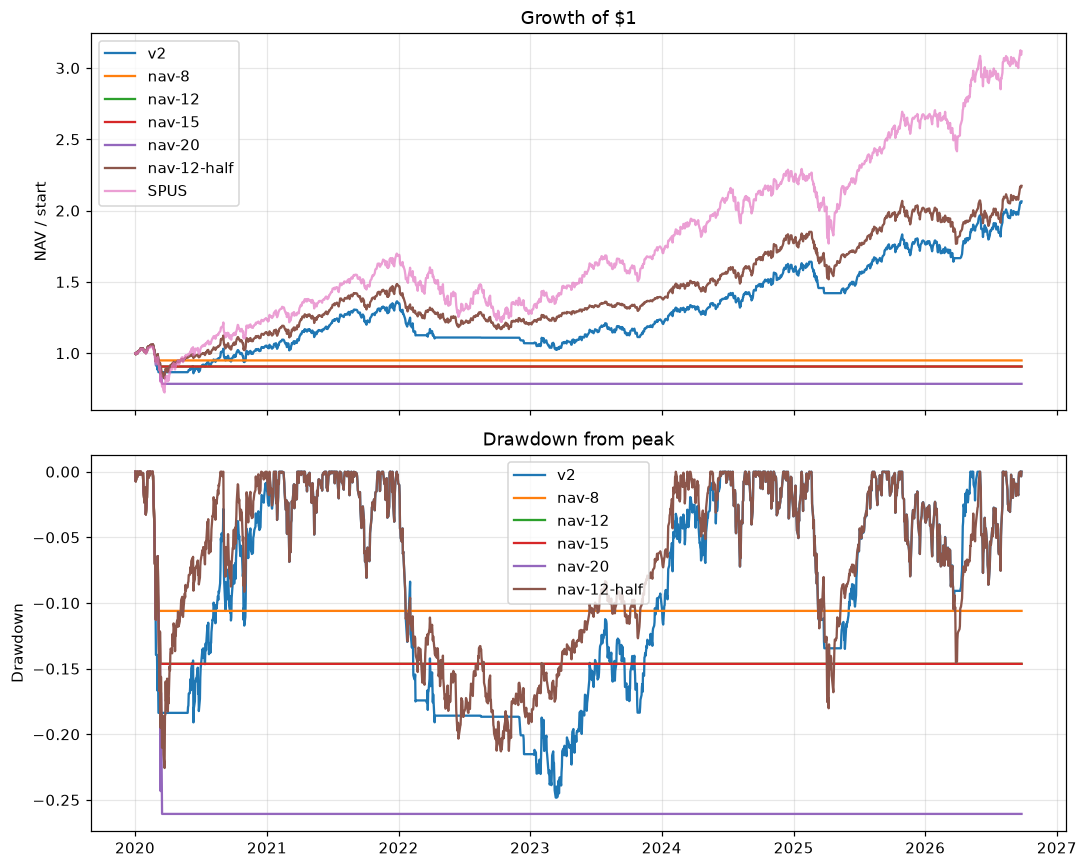

wrote figures/nav-and-drawdown.png


In [6]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)
spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    axes[0].plot(nav.index, nav / nav.iloc[0], label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)
axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].set_ylabel("NAV / start")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].set_ylabel("Drawdown")
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


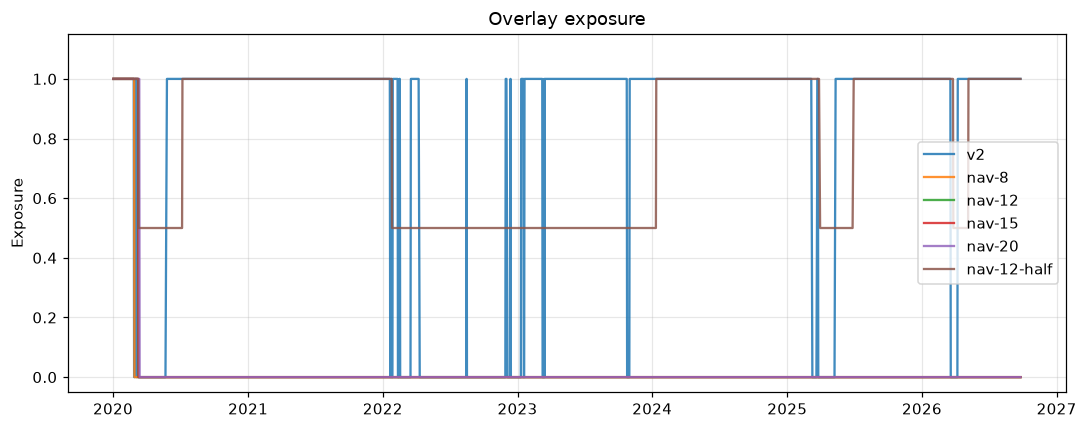

wrote figures/exposure.png


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    ax.plot(nav["date"], nav["exposure"], label=book.spec.id, alpha=0.85)
ax.set_title("Overlay exposure")
ax.set_ylabel("Exposure")
ax.set_ylim(-0.05, 1.15)
ax.legend()
fig.tight_layout()
fig.savefig(figures / "exposure.png", dpi=140)
plt.show()
print("wrote", figures / "exposure.png")


,v2,nav-8,nav-12,nav-15,nav-20,nav-12-half,SPUS
year,,,,,,,
2020,0.0528,-0.0510,-0.0938,-0.0938,-0.2151,0.1466,0.2399
2021,0.2831,0.0000,0.0000,0.0000,0.0000,0.2832,0.3562
2022,-0.2080,0.0000,0.0000,0.0000,0.0000,-0.1780,-0.2276
2023,0.1525,0.0000,0.0000,0.0000,0.0000,0.1515,0.3420
2024,0.2741,0.0000,0.0000,0.0000,0.0000,0.2723,0.2649
2025,0.1250,0.0000,0.0000,0.0000,0.0000,0.1255,0.1978
2026,0.1681,0.0000,0.0000,0.0000,0.0000,0.0901,0.1802


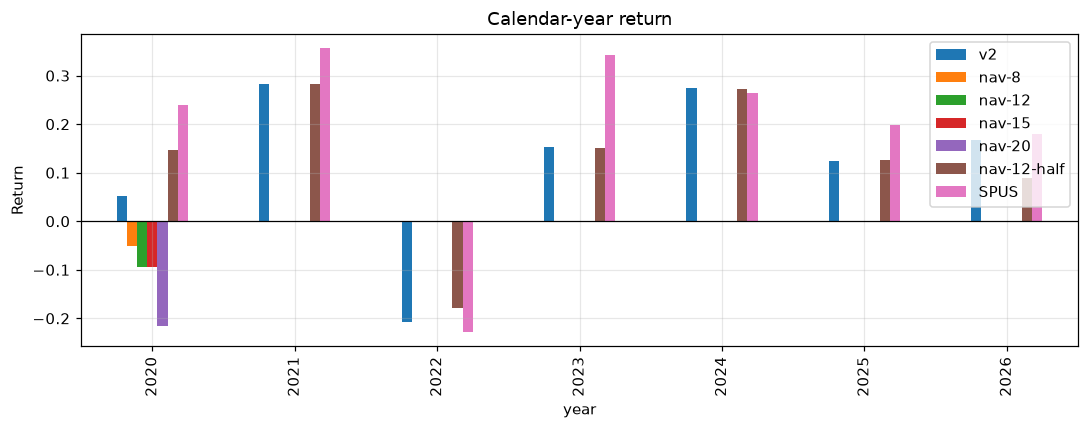

wrote figures/calendar-returns.png


In [8]:
calendar = pd.concat(
    {book.spec.id: yearly(book.nav_series())["return"] for book in books},
    axis=1,
)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_title("Calendar-year return")
ax.set_ylabel("Return")
ax.axhline(0, color="black", lw=0.8)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Conclusion

**Would we run this?** Not as a cut to cash. A trailing stop on this NAV that goes to **0% equity** fires once in 2020 and **never turns back on** — idle cash yields 0%, so the book cannot recover the 8–20% it just locked in. 2021–26 print 0%. That fails 2023 by a mile. The only pass is **nav-12-half**: same 12% trigger, keep half the FCF list while braked.

**What we asked.** The SPY 200-day still lost about −21% in 2022 and −19% inside 2020. This paper turned the SMA off and cut when *this* book's prior NAV was X% below its own peak, then waited until half that loss was recovered. Ladder X in {8, 12, 15, 20}, plus 12% to 50% exposure.

**What happened.**

- The cash stops bind, and that is the problem. Nav-8 / 12 / 15 / 20 each cut **once**, sit in cash ~1,640 sessions, and finish negative (−5% to −22% total). Max drawdown looks “better” on the tight stops (−11% / −17%) because the book is already dead. All four are **killed** (train Calmar and 2023).
- Nav-12-half **passes**. Calmar **0.54** versus v2 0.46. Max drawdown −22.6% versus −24.8%. 2022 is −17.8% versus v2 −20.8%. 2023 matches v2 (~15%). Average exposure stays ~0.80. It is not a costume SMA: 4 cuts versus v2's 18, and 2021–25 still look like the FCF book.
- Recovering from a cash stop needs either a yield (paper 21) or leftover equity. With 0% cash, a full flatten is a one-way door.

**What this means for the fund.** A mandate-shaped brake is not “ignore SPY, go to cash after our NAV drops.” That rule ate 2023. If we want a path brake, keep **partial exposure** (or pay Halal cash while flat). Do not replace the SMA with a 8–20% cash trailing stop on this sample.

**Live rule.** Keep the v2 SPY 200-day. Do not promote `nav_brake` to cash. Nav-12-half is a research candidate, not a live overlay, until it is tested with paper 21's yield and against paper 23's SPUS switch. Two overlays at once is a later paper.
